# PyTorch Workflow

It is about Pytorch end-to-end workflow
- Book version:https://www.learnpytorch.io/01_pytorch_workflow/
- Video version:https://www.youtube.com/watch?v=V_xro1bcAuA&t=21923s



In [ ]:
import pprint

what_were_covering = {
    1: "data (prepare and load)",
    2: "build model",
    3: "fitting the model to data (trianing)",
    4: "making predictions and evaluting a model (inference)",
    5: "saving and loading a model",
    6: "putting it all together"
}

pprint.pprint(what_were_covering)

{1: 'data (prepare and load)',
 2: 'build model',
 3: 'fitting the model to data (trianing)',
 4: 'making predictions and evaluting a model (inference)',
 5: 'saving and loading a model',
 6: 'putting it all together'}


In [ ]:
import torch
from torch import nn # nn contains all of PyTorch's building blocks for nueral networks
import matplotlib.pyplot as plt

# Check PyTorch Version
torch.__version__

'2.11.0+cpu'

## 1. Data (preparing and loading)

Data can be almost be almost anything... in machine learning

- Excel speadsheet
- Image of any kind
- Videos (Youtube has a lot of data...)
- Audio like songs or podcasts
- DNA
- Text

Machine learning is a game of two parts:
1. Get data into a numerical representation.
2. Build a model to learn patterns in that numerical representation.

To showcase this, let's create some *known* data using the linear regression formula.

We'll use a linear regression formula to make a straight line with known **parameters**.

In [ ]:
# Create known parameters
weight = 0.7
bias = 0.3

# Create
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

print(X[:10])
print(y[:10])
print(len(X))
print(len(y))

tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800]])
tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560],
        [0.3700],
        [0.3840],
        [0.3980],
        [0.4120],
        [0.4260]])
50
50


### (1) Splitting data into training and test sets (one of the most important concept in machine learning in general)

- training set (Course materials, ~60-80%)
- validation set (Practice exam, ~10-20%)
- test set (Final exam, ~10-20%)  

**The ultimate goal**: <mark>**Generalization**</mark> (The ability for a machine learning model to perform well on data it hasn't seen before)

Let's create a training and test set with our data

In [ ]:
# Create a train/test split
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

### (2) Visualize the data  

How might we better visualzied our data?

This is where the data explorer's motto comes in!  

"Visualize, visualize, visualize!"

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_predictions(train_data=X_train,
           train_labels=y_train,
           test_data=X_test,
           test_labels=y_test,
           predictions=None):
  """
  Plots training data, test data and compares predictions.
  """
  plt.figure(figsize=(10,7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")

  # Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

  # Are there predictions?
  if predictions is not None:
    # Plot the predictuons in red if they exist
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  # Show the legend
  plt.legend(prop={"size":14});




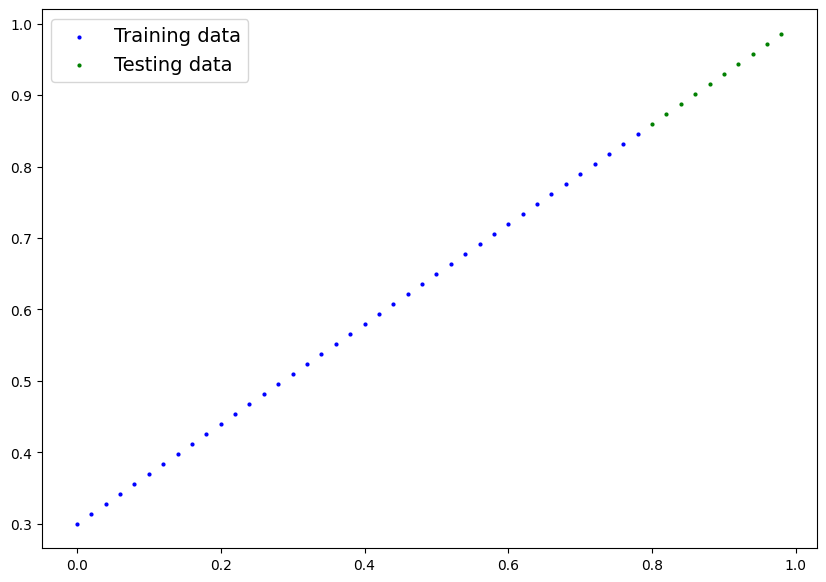

In [ ]:
plot_predictions();



## 2. Build a model  
Our first PyTorch model!  

This is very exciting... let's do it!  

What our model does:
- Start with random values (weights & bias)
- Look at training data and adjust the random values to better represent (or get closer to) the ideal values (the weight & bias values we used to create the data)  

How does it do so?  

Through two main algorithms:  
1. Gradient Descent (why we make sure `requires_grad=True`)
2. Backpropagation

In [ ]:
from torch import nn

# Create linear regression model class
class LinearRegressionModel(nn.Module):  # <- subclass nn.Module, containing all the building blocks for neural networks
  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(
        1,             # <- start with a random weight, in this case it is a scalar
        requires_grad=True,     # <- can we update this value through gradient descent?
        dtype=torch.float      # <- pytorch loves float32 by default
    ))

    self.bias = nn.Parameter(torch.randn(
        1,
        requires_grad=True,
        dtype=torch.float
    ))

   # Forward method to define the computation in the model
  def forward(self, x:torch.Tensor) -> torch.Tensor:  # <- "x" is the input data/training data
    return self.weights * x + self.bias



`require_grad = True` means PyTorch will track the gradients of this specific parameter for use with `torch.autograd` and gradient descent(for many `torch.nn` modules, `requires_grad=True` is set by default

### Pytorch model building essentials

- `torch.nn` - contains all of the buildings for computational graphs( a neural network can be considered as a computational graph)

- `torch.nn.Parameter` - what parameters should our model try and learn, often a PyTorch layer from torch.nn will set these for us

- `torch.nn.Module` - The base class for all neural network modules, if you subclass it, you should overwrite forward()

- `torch.optim` - this where the optimizers in PyTorch live, they will help with gradient descent

- `def forward()` - All nn.Module subclasses require you to overwrite forward(), this method defines what happens in the forward computation

Here is a PyTorch cheat sheet for you to refer: https://pytorch-cn.com/tutorials/beginner/ptcheat.html



### Checking the contents of our PyTorch model

Now we've create a model, let's see what's inside...  

So we can check our model parameters or what's inside our model using `.parameters()`



In [ ]:
# Create a random seed
torch.manual_seed(42)

# Create an instance of the model (this is a subclass of nn.Module)
model_0 = LinearRegressionModel()

# Check out the parameters
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
# List name parameters
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

### Making predictions using `torch.inference_mode()`

To check our model's predictive power, let's see how well it predicts `y_test` based on `X_test`  

When we pass data through our model, it's going to run it through the `forward()` method  

See more on inference mode here:  https://x.com/PyTorch/status/1437838231505096708



In [ ]:
y_preds = model_0(X_test)
y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]], grad_fn=<AddBackward0>)

In [ ]:
# Make predictions with model
with torch.inference_mode():    # A context manager you can use when doing inference/predictions, we don't need to keep track of the gradient
  y_preds = model_0(X_test)

# You can also do something similar with torch.no_grad(), however, torch.inference_mode() is preferred
# with torch.no_grad():
#   y_preds = model_0(X_test)

y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

In [ ]:
y_test

tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

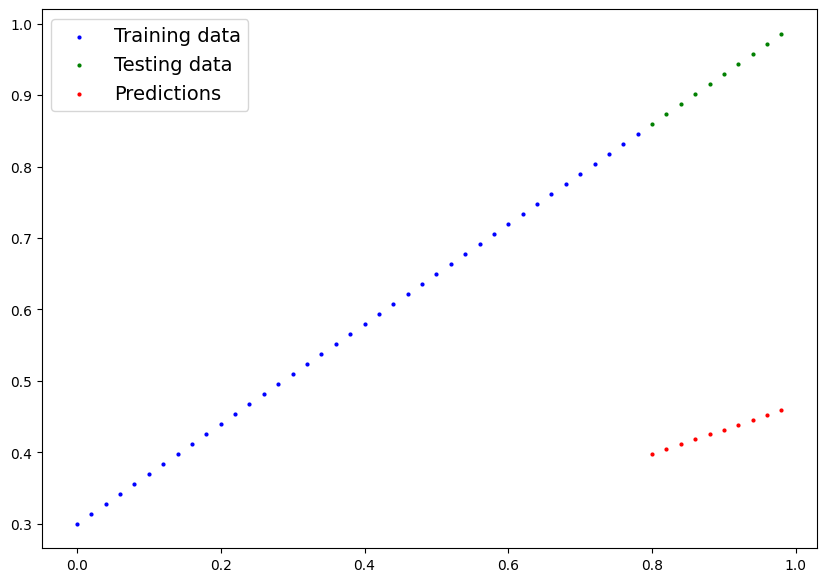

In [ ]:
plot_predictions(predictions=y_preds)

## 3. Train model

The whole idea of training is for a model to move from some **unknown** parameters (these may be random) to some known parameters.  

Or in other words from a poor representation of the data to a better representations of the data.  

One way to measure how poor or how wrong your models predictions are is to use a loss function.

<mark>**NOTE**</mark>: Loss function may also be called cost function or criterion in different areas. For our case, we are going to refer to it as a loss function.  

Things we need to train a model:

- **Loss Function:** A function to measure how wrong your model's predictions are to the ideal outputs, lower is better - https://docs.pytorch.org/docs/main/nn.html#loss-functions

- **Optimizer:** Takes into account the loss of a model and adjusts the model's parameters (e.g. weight & bias in our case) to improve the loss function - https://docs.pytorch.org/docs/main/optim.html

  - Inside the optimizer you'll often have to set two parameters:
    - `params` - the model parameters you'd like to optimize, for example `params=model_0.parameters()`
    - `lr`(learning rate) - the learning rate is a hyperparameter that defines how big/small the optimizer changes the parameters with each step (a small `lr` results in small changes, a large `lr` results in large changes)

And specifically for PyTorch, we need:  

- A trainig loop

- A testing loop


In [ ]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
# Check out our model's parameters (a parameter is a value that the model sets itself)
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [ ]:
# Setup a loss function
loss_fn = nn.L1Loss()

# Setup an optimizer (stochastic gradient descent)
optimizer = torch.optim.SGD(
    params=model_0.parameters(),  # we want to optimize the parameters present in our model
    lr=0.01    # lr = learning rate = possibly the most important hyperparameters you can set
)

- For a regression problem, a loss function of `nn.L1Loss()` and an optimizer like `torch.optim.SGD()` will be sufficient
- For a classification problem, you'll likely to use a loss function of `nn.BCELoss()` (binary cross entropy loss)

### Building a training loop (and a testing loop) in PyTorch  

A couple of things we nedd in a training loop:  

0. Loop through the data
1. Forward pass (this involves data moving through our model's `forward()` functions) - also called forward propagation
2. Calculate the loss (compare forward pass predictions to ground truth labels)
3. Optimizer zero grad
4. Loss backward - move backwards through the networks to calculate the gradients of each of the parameters of our model with respect to the loss
5. Optimizer step - use the optimizer to adjust our model's parameters to try and improve the loss (**gradient descent**)

In [ ]:
torch.manual_seed(42)

# An epoch is one loop through the data... (this is a hyperparameter because we've set it by ourselves)
epochs = 200

# Track different values
epoch_count = []
train_loss_values = []
test_loss_values = []

# 0. Loop through the data
for epoch in range(epochs):
  # set the model to training mode:
  model_0.train()  # train mode in PyTorch sets all parameters that require gradients to require gradients

  # 1. Forward pass
  y_pred = model_0(X_train)

  # 2. Calculate the loss
  train_loss = loss_fn(y_pred, y_train)

  # 3. Optimizer zero grad
  optimizer.zero_grad()

  # 4. Perform backpropagation on the loss with respect to the parameters of the model
  train_loss.backward()

  # 5. Step the optimizer (perform gradient descent)
  optimizer.step()  # by default the optimizer changes will accumulate through the loop so... we have to zero them above in step 3 for the next iteration of the loop

  ### Testing
  model_0.eval()  # turns off different settings in the model not needed for evaluation/testing (dropout/batch norm layers)
  with torch.inference_mode():  # turns off gradient tracking & a couple more things behind the scenes
    # 1. Do the forward pass
    test_pred = model_0(X_test)

    # 2. Calculate the loss
    test_loss = loss_fn(test_pred, y_test)

  # Print out what's happening
  if epoch % 10 == 0:
    epoch_count.append(epoch)
    train_loss_values.append(train_loss)
    test_loss_values.append(test_loss)
    print(f"Epoch:{epoch} | Train loss:{train_loss} | Test loss:{test_loss}")
    # print out model state_dict()
    print(model_0.state_dict())


Epoch:0 | Train loss:0.31288138031959534 | Test loss:0.48106518387794495
OrderedDict({'weights': tensor([0.3406]), 'bias': tensor([0.1388])})
Epoch:10 | Train loss:0.1976713240146637 | Test loss:0.3463551998138428
OrderedDict({'weights': tensor([0.3796]), 'bias': tensor([0.2388])})
Epoch:20 | Train loss:0.08908725529909134 | Test loss:0.21729660034179688
OrderedDict({'weights': tensor([0.4184]), 'bias': tensor([0.3333])})
Epoch:30 | Train loss:0.053148526698350906 | Test loss:0.14464017748832703
OrderedDict({'weights': tensor([0.4512]), 'bias': tensor([0.3768])})
Epoch:40 | Train loss:0.04543796554207802 | Test loss:0.11360953003168106
OrderedDict({'weights': tensor([0.4748]), 'bias': tensor([0.3868])})
Epoch:50 | Train loss:0.04167863354086876 | Test loss:0.09919948130846024
OrderedDict({'weights': tensor([0.4938]), 'bias': tensor([0.3843])})
Epoch:60 | Train loss:0.03818932920694351 | Test loss:0.08886633068323135
OrderedDict({'weights': tensor([0.5116]), 'bias': tensor([0.3788])})
E

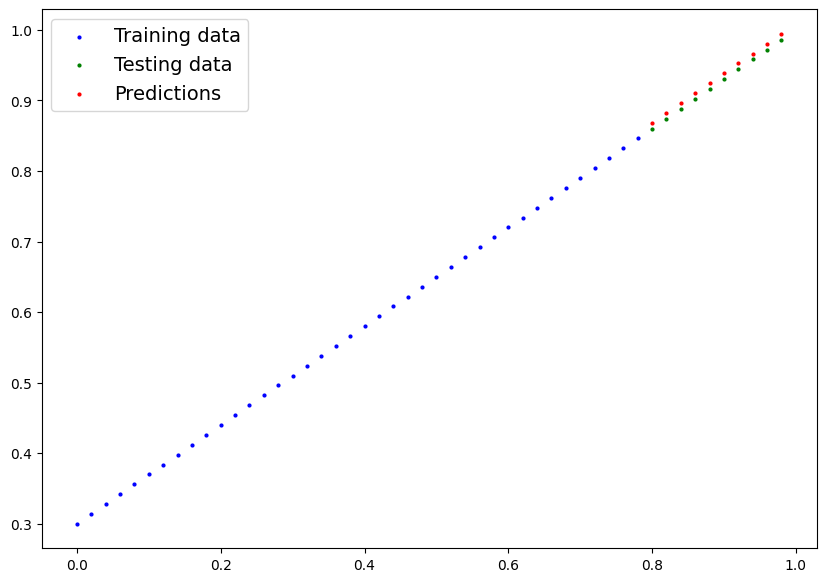

In [ ]:
with torch.inference_mode():
  y_pred_new = model_0(X_test)

plot_predictions(predictions=y_pred_new)

/tmp/ipykernel_539/1367110214.py:2: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  plt.plot(epoch_count, np.array(torch.tensor(train_loss_values).numpy()), label="Train loss")


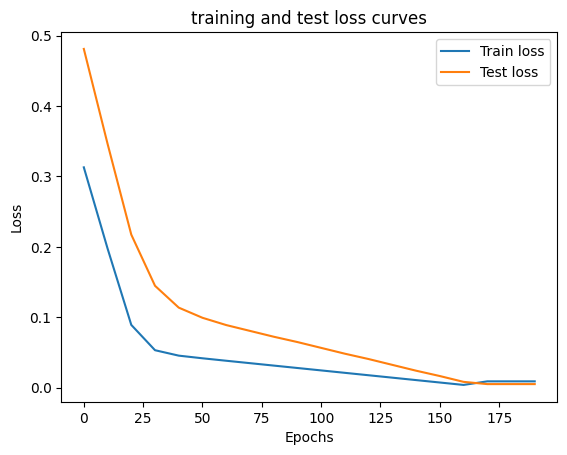

In [ ]:
# Plot the loss curve
plt.plot(epoch_count, np.array(torch.tensor(train_loss_values).numpy()), label="Train loss")
plt.plot(epoch_count, np.array(torch.tensor(test_loss_values).numpy()), label="Test loss")
plt.title("training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();

## 4. Saving and loading a model in PyTorch

There are three main method you should learn about for saving and loading models in PyTorch.  

1. `torch.save()` - allows you save a PyTorch object in Python's pickle format  

2. `torch.load()` - allows you load a saved PyTorch object

3. `torch.nn.Module.load_state_dict()` - this allows to load a model's saved state dictionary

PyTorch save & load code tutorial + extra-curriculum:  
https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html

### Saving a PyTorch model's `state_dic()`  

`state_dict()` returns a dictionary, which records the key status of the model and the optimizer.  

For the model `nn.Module`, `state_dict()` mainly includes:  

  - Parameters: weights and bias in the whole nueral network

  - Buffers: e.g. `running_mean` and `running_var` in BatchNorm layer  

For the optimizer `torch.optim`, `state_dict` mainly includes:

  - The status of the optimizer

  - The hyperparameters( `lr`, `weight_decay`)  

Let's see how we can do that in a few steps:
  1. We'll create a directory for saving models to called `models` using Python's `pathlib` model.  

  2. We'll create a file path to save the model  

  3. We'll call `torch.save(obj, f)` where `obj` is the target model's `state_dict()` and `f` is the filename of where to save the model

> <mark>Note</mark>: It is common convention for PyTorch saved models or objects to end with `.pt` or `.pth`, like `saved_model_01.pth`  

If you want to learn more: https://docs.pytorch.org/docs/2.14/generated/torch.save.html



In [ ]:
# Saving our PyTorch model
from pathlib import Path

# 1. Create models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create model save path
MODEL_NAME = "01_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(
    obj=model_0.state_dict(),
    f=MODEL_SAVE_PATH
)

Saving model to: models/01_pytorch_workflow_model_0.pth


In [ ]:
!ls -l models

total 4
-rw-r--r-- 1 root root 2117 Nov  2 17:43 01_pytorch_workflow_model_0.pth


### Loading a PyTorch model

Since we saved our model's `state_dict()` rather than the entire model, we'll create a new instance of our model class and load the saved `state_dic()` into that.

In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.6990])), ('bias', tensor([0.3093]))])

In [ ]:
# To load in a saved stated_dict we have to instantiate a new instance of our model class
loaded_model_0 = LinearRegressionModel()

# Load the saved state_dic of model_0 (this will update the new instance with updated parameters)
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [ ]:
loaded_model_0.state_dict()

OrderedDict([('weights', tensor([0.6990])), ('bias', tensor([0.3093]))])

In [ ]:
# Make some predictions with our loaded model
loaded_model_0.eval()
with torch.inference_mode():
  loaded_model_preds = loaded_model_0(X_test)

loaded_model_preds

tensor([[0.8685],
        [0.8825],
        [0.8965],
        [0.9105],
        [0.9245],
        [0.9384],
        [0.9524],
        [0.9664],
        [0.9804],
        [0.9944]])

In [ ]:
# Make some predictions with our current model
model_0.eval()
with torch.inference_mode():
  y_preds = model_0(X_test)

y_preds

tensor([[0.8685],
        [0.8825],
        [0.8965],
        [0.9105],
        [0.9245],
        [0.9384],
        [0.9524],
        [0.9664],
        [0.9804],
        [0.9944]])

In [ ]:
# Compare loaded model preds with original model preds
y_preds == loaded_model_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

practice: https://www.deep-ml.com/problems/15?utm_source=chatgpt.com